# 03 — Rule-Based baseline
Baseline luật minh bạch để so sánh với mô hình học máy. Đây không phải mô hình được train và không được trình bày như AI.

In [1]:
from pathlib import Path
import json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform, sklearn
import importlib
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from securaai_ml.data import load_training_data
import securaai_ml.modeling as modeling_module
importlib.reload(modeling_module)  # tránh module cache cũ khi source vừa được cập nhật
from securaai_ml.modeling import (candidate_factories, decision_scores, parameter_grids,
    teaching_candidate_factories, teaching_parameter_grids)
from securaai_ml.schema import MODEL_FEATURES, TARGET_COLUMN, GROUP_COLUMN
from securaai_ml.train import temporal_train_validation_test

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data, audit = load_training_data(ROOT / 'data' / 'raw')
train, validation, test = temporal_train_validation_test(data)
X_train, y_train = train.loc[:, MODEL_FEATURES], train[TARGET_COLUMN]
X_validation, y_validation = validation.loc[:, MODEL_FEATURES], validation[TARGET_COLUMN]
groups = train[GROUP_COLUMN]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
audit

DatasetAudit(rows=102011, malicious=63792, benign=38219, groups=40, invalid_timestamps=0)

## 1. Luật chỉ dùng feature hợp lệ
Cộng điểm khi có command line, parent command, hash, target file, IP nguồn hoặc event status bất thường. Không dùng MITRE tag/Wazuh rule tạo nhãn.

In [2]:
def rule_score(frame):
    return (2*frame['has_command_line'] + frame['has_parent_command_line'] + 2*frame['has_hashes'] + frame['has_target_file'] + frame['has_source_ip'] + frame['event_status'].isin(['failure','failed','denied']).astype(int)).to_numpy(dtype=float)
validation_score=rule_score(X_validation)
validation_score[:10]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

## 2. Chọn ngưỡng trên Validation

In [3]:
rows=[]
for threshold in np.arange(1,8):
    pred=(validation_score>=threshold).astype(int)
    rows.append({'threshold':threshold,'precision':precision_score(y_validation,pred,zero_division=0),'recall':recall_score(y_validation,pred,zero_division=0),'f1':f1_score(y_validation,pred,zero_division=0),'f2':fbeta_score(y_validation,pred,beta=2,zero_division=0)})
threshold_table=pd.DataFrame(rows); display(threshold_table)
locked_threshold=int(threshold_table.sort_values(['f2','recall'],ascending=False).iloc[0].threshold)
print('Locked threshold:',locked_threshold)

,threshold,precision,recall,f1,f2
0,1,0.999902,0.925574,0.961304,0.939542
1,2,0.999819,0.499277,0.665983,0.554830
2,3,0.999794,0.439230,0.610329,0.494704
3,4,1.000000,0.439230,0.610368,0.494714
4,5,1.000000,0.439230,0.610368,0.494714
5,6,0.000000,0.000000,0.000000,0.000000
6,7,0.000000,0.000000,0.000000,0.000000


Locked threshold: 1


## 3. Test sau khi khóa luật/ngưỡng

,TEST
accuracy,0.792490
precision,0.999329
recall,0.636030
f1,0.777325
f2,0.685901
roc_auc,0.817741
average_precision,0.842959


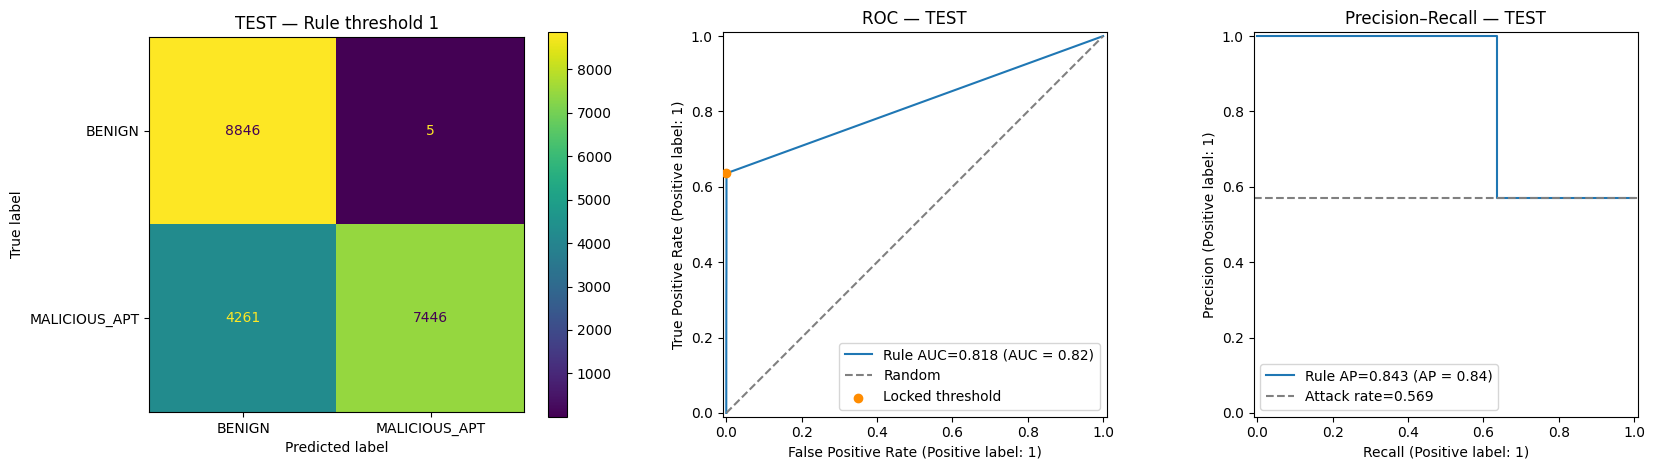

Rule score chỉ có 4 mức nên ROC/PR có ít điểm hơn mô hình xác suất.


In [4]:
X_test,y_test=test.loc[:,MODEL_FEATURES],test[TARGET_COLUMN]
test_score=rule_score(X_test); test_pred=(test_score>=locked_threshold).astype(int)
result=pd.Series({'accuracy':accuracy_score(y_test,test_pred),'precision':precision_score(y_test,test_pred,zero_division=0),'recall':recall_score(y_test,test_pred,zero_division=0),'f1':f1_score(y_test,test_pred,zero_division=0),'f2':fbeta_score(y_test,test_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_test,test_score),'average_precision':average_precision_score(y_test,test_score)})
display(result.to_frame('TEST'))
tn,fp,fn,tp=confusion_matrix(y_test,test_pred,labels=[0,1]).ravel()
fig,axes=plt.subplots(1,3,figsize=(17,4.8))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['BENIGN','MALICIOUS_APT'],ax=axes[0]); axes[0].set_title(f'TEST — Rule threshold {locked_threshold}')
RocCurveDisplay.from_predictions(y_test,test_score,name=f"Rule AUC={result['roc_auc']:.3f}",ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray',label='Random'); axes[1].scatter([fp/(fp+tn)],[tp/(tp+fn)],color='darkorange',zorder=5,label='Locked threshold'); axes[1].set_title('ROC — TEST'); axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_test,test_score,name=f"Rule AP={result['average_precision']:.3f}",ax=axes[2]); axes[2].axhline(float(y_test.mean()),ls='--',color='gray',label=f'Attack rate={y_test.mean():.3f}'); axes[2].set_title('Precision–Recall — TEST'); axes[2].legend()
plt.tight_layout(); plt.show()
print('Rule score chỉ có',len(np.unique(test_score)),'mức nên ROC/PR có ít điểm hơn mô hình xác suất.')

## 4. Kết luận
Rule-Based là baseline giải thích được nhưng khó bao phủ hành vi mới. Chỉ dùng để chứng minh mô hình học máy có cải thiện thực sự so với luật thủ công.